<a href="https://colab.research.google.com/github/jayaraksha/DEEP-LEARNING-SEM-5-/blob/main/24bad044_dl_exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow version: 2.21.0
Training shape: (60000, 28, 28) Test shape: (10000, 28, 28)
Data type: uint8 Original range: (np.uint8(0), np.uint8(255))


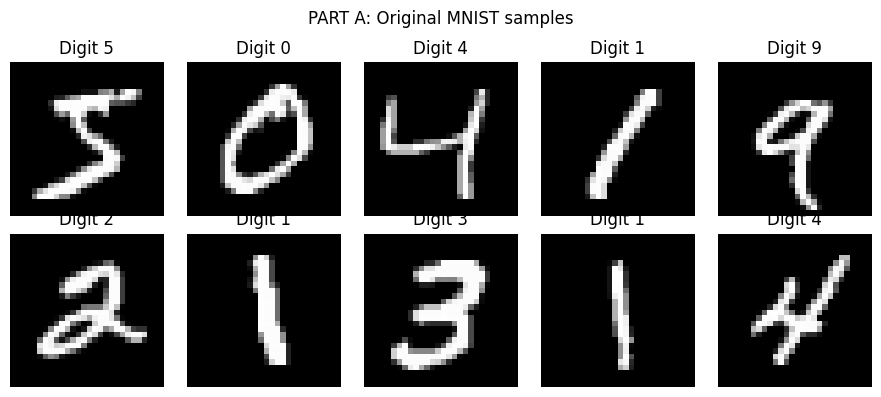

Normalized shape: (60000, 28, 28, 1)
Normalized range: (-1.0, 1.0)
Number of training batches: 234
jayaraksha 24BAD044


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print("Training shape:", x_train.shape, "Test shape:", x_test.shape)
print("Data type:", x_train.dtype, "Original range:", (x_train.min(), x_train.max()))

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, img, label in zip(axes.ravel(), x_train[:10], y_train[:10]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Digit {label}")
    ax.axis("off")
plt.suptitle("PART A: Original MNIST samples")
plt.tight_layout()
plt.show()

x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train[..., np.newaxis]    # (60000, 28, 28, 1)
BUFFER_SIZE = 60000
BATCH_SIZE = 256
train_ds = (tf.data.Dataset.from_tensor_slices(x_train)
            .shuffle(BUFFER_SIZE, seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE, drop_remainder=True)
            .prefetch(tf.data.AUTOTUNE))
print("Normalized shape:", x_train.shape)
print("Normalized range:", (float(x_train.min()), float(x_train.max())))
print("Number of training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("jayaraksha 24BAD044")

In [ ]:
NOISE_DIM = 100

def build_generator():
    noise = layers.Input(shape=(NOISE_DIM,), name="noise_vector")
    x = layers.Dense(7 * 7 * 128, use_bias=False)(noise)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Reshape((7, 7, 128))(x)
    x = layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    image = layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh")(x)
    return Model(noise, image, name="Generator")

def build_discriminator():
    image = layers.Input(shape=(28, 28, 1), name="input_image")
    x = layers.Conv2D(64, 5, strides=2, padding="same")(image)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv2D(128, 5, strides=2, padding="same")(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Flatten()(x)
    logit = layers.Dense(1)(x)
    return Model(image, logit, name="Discriminator")

generator = build_generator()
discriminator = build_discriminator()
gan = Model(generator.input, discriminator(generator.output), name="Combined_GAN")
loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4, beta_1=0.5)
d_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4, beta_1=0.5)
print("\nGENERATOR SUMMARY")
generator.summary()
print("\nDISCRIMINATOR SUMMARY")
discriminator.summary()
print("\nCOMBINED GAN SUMMARY")
gan.summary()
print("Generated image shape:", generator(tf.random.normal([1, NOISE_DIM]), training=False).shape)
print("jayaraksha 24BAD044")


GENERATOR SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noise_vector (InputLayer)       │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 858,945 (3.28 MB)

 Trainable params: 846,273 (3.23 MB)

 Non-trainable params: 12,672 (49.50 KB)

... (9 outputs left out)

 Total params: 1,071,810 (4.09 MB)

 Trainable params: 1,059,138 (4.04 MB)

 Non-trainable params: 12,672 (49.50 KB)

Generated image shape: (1, 28, 28, 1)
jayaraksha 24BAD044


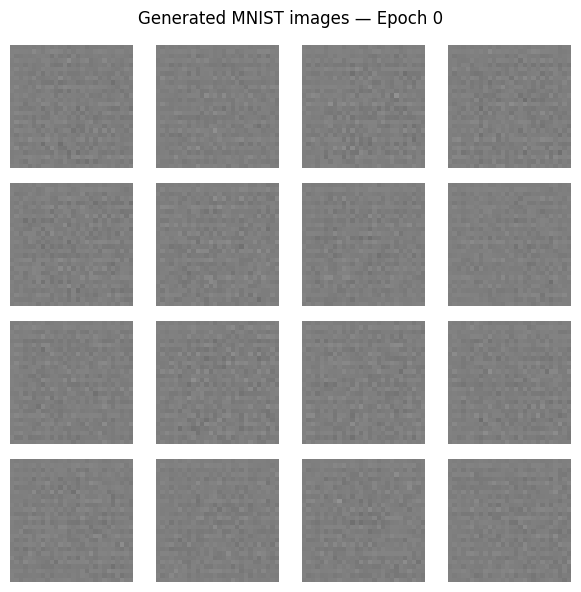

Epoch 01/10 | Generator loss: 0.7912 | Discriminator loss: 1.0376


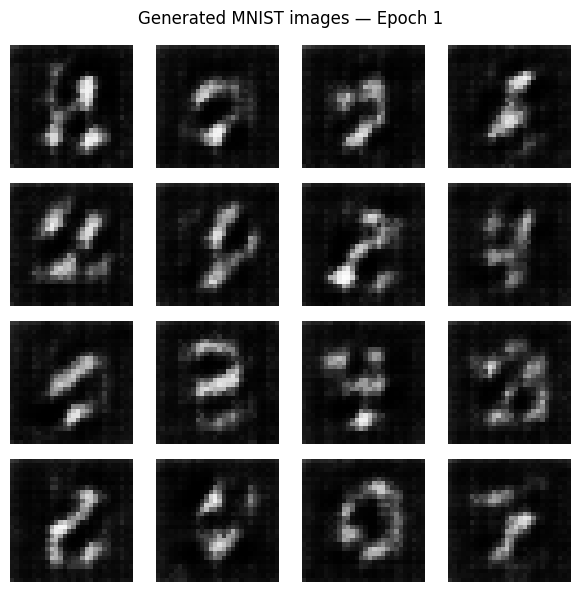

Epoch 02/10 | Generator loss: 0.8232 | Discriminator loss: 1.2377
Epoch 03/10 | Generator loss: 0.8131 | Discriminator loss: 1.2605
Epoch 04/10 | Generator loss: 0.8380 | Discriminator loss: 1.2395
Epoch 05/10 | Generator loss: 0.8712 | Discriminator loss: 1.2108


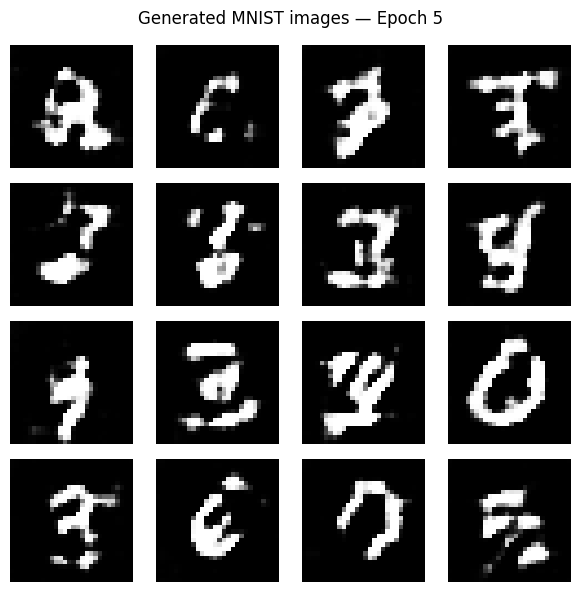

Epoch 06/10 | Generator loss: 0.9200 | Discriminator loss: 1.1641
Epoch 07/10 | Generator loss: 0.9647 | Discriminator loss: 1.1266
Epoch 08/10 | Generator loss: 0.9940 | Discriminator loss: 1.1152
Epoch 09/10 | Generator loss: 0.9798 | Discriminator loss: 1.1477
Epoch 10/10 | Generator loss: 0.9425 | Discriminator loss: 1.1864


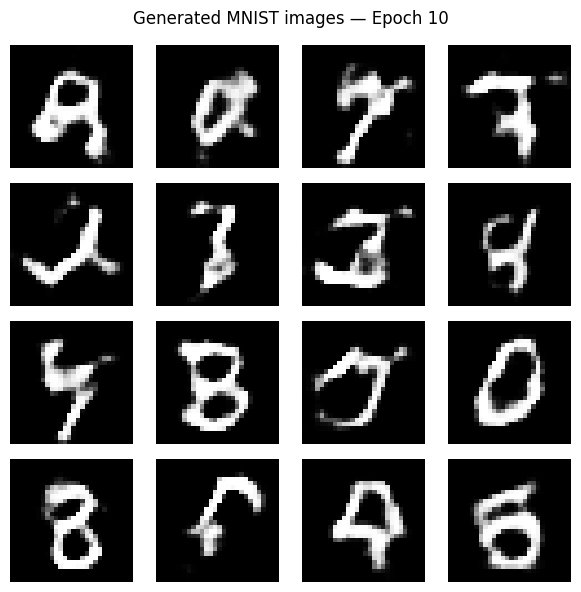


Loss history
 epoch  generator_loss  discriminator_loss
     1        0.791181            1.037555
     2        0.823166            1.237658
     3        0.813055            1.260451
     4        0.838026            1.239491
     5        0.871167            1.210776
     6        0.920005            1.164124
     7        0.964739            1.126570
     8        0.993980            1.115161
     9        0.979807            1.147675
    10        0.942461            1.186440


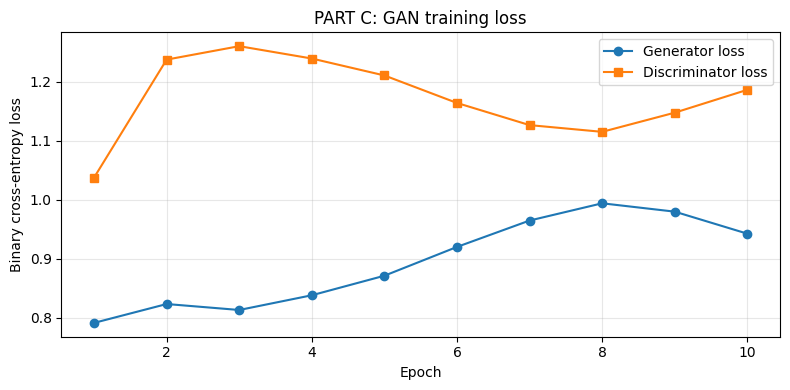

jayaraksha 24BAD044


In [ ]:
EPOCHS = 10   # Increase to 20–30 for potentially clearer results (longer runtime).
FIXED_NOISE = tf.random.normal([16, NOISE_DIM], seed=SEED)

def discriminator_loss(real_logits, fake_logits):
    real_loss = loss_fn(tf.ones_like(real_logits), real_logits)
    fake_loss = loss_fn(tf.zeros_like(fake_logits), fake_logits)
    return real_loss + fake_loss

def generator_loss(fake_logits):
    return loss_fn(tf.ones_like(fake_logits), fake_logits)

@tf.function
def train_step(real_images):
    noise = tf.random.normal([tf.shape(real_images)[0], NOISE_DIM])
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)
        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake_images, training=True)
        g_loss = generator_loss(fake_logits)
        d_loss = discriminator_loss(real_logits, fake_logits)
    g_grads = gen_tape.gradient(g_loss, generator.trainable_variables)
    d_grads = disc_tape.gradient(d_loss, discriminator.trainable_variables)
    g_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))
    d_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    return g_loss, d_loss

def show_generated_images(epoch, noise=FIXED_NOISE):
    predictions = generator(noise, training=False).numpy()
    predictions = np.clip((predictions + 1.0) / 2.0, 0.0, 1.0)
    fig, axes = plt.subplots(4, 4, figsize=(6, 6))
    for ax, image in zip(axes.flat, predictions):
        ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    plt.suptitle(f"Generated MNIST images — Epoch {epoch}")
    plt.tight_layout()
    plt.show()

history = {"epoch": [], "generator_loss": [], "discriminator_loss": []}
show_generated_images(0)
for epoch in range(1, EPOCHS + 1):
    g_avg = tf.keras.metrics.Mean()
    d_avg = tf.keras.metrics.Mean()
    for real_batch in train_ds:
        g_loss, d_loss = train_step(real_batch)
        g_avg.update_state(g_loss)
        d_avg.update_state(d_loss)
    history["epoch"].append(epoch)
    history["generator_loss"].append(float(g_avg.result()))
    history["discriminator_loss"].append(float(d_avg.result()))
    print(f"Epoch {epoch:02d}/{EPOCHS} | Generator loss: {g_avg.result():.4f} | Discriminator loss: {d_avg.result():.4f}")
    if epoch in {1, 5, EPOCHS}:
        show_generated_images(epoch)

loss_df = pd.DataFrame(history)
print("\nLoss history")
print(loss_df.to_string(index=False))
plt.figure(figsize=(8, 4))
plt.plot(loss_df["epoch"], loss_df["generator_loss"], marker="o", label="Generator loss")
plt.plot(loss_df["epoch"], loss_df["discriminator_loss"], marker="s", label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("PART C: GAN training loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("jayaraksha 24BAD044")

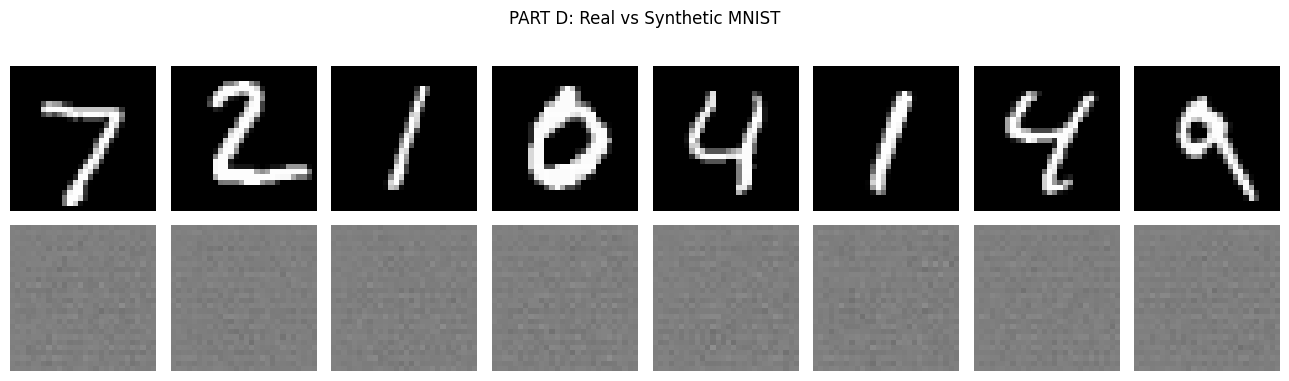

Noise vector dimension: 100
Synthetic image dimensions: (16, 28, 28, 1)
Mean across-image pixel standard deviation: 0.0114
Interpretation: visually inspect digit recognizability and variety; this number alone cannot prove GAN quality.
Saved: gan_generator.keras, gan_training_losses.csv
jayaraksha 24BAD044


In [ ]:
new_noise = tf.random.normal([16, NOISE_DIM], seed=2026)
synthetic = generator(new_noise, training=False).numpy()
synthetic = np.clip((synthetic + 1) / 2, 0, 1)

fig, axes = plt.subplots(2, 8, figsize=(13, 4))
for i in range(8):
    axes[0, i].imshow(x_test[i], cmap="gray", vmin=0, vmax=255)
    axes[1, i].imshow(synthetic[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Real", fontsize=12)
axes[1, 0].set_ylabel("Generated", fontsize=12)
plt.suptitle("PART D: Real vs Synthetic MNIST")
plt.tight_layout()
plt.show()

# Optional simple diversity indicator (not a perceptual quality metric):
flattened = synthetic.reshape(16, -1)
mean_pixel_std = float(np.std(flattened, axis=0).mean())
print("Noise vector dimension:", NOISE_DIM)
print("Synthetic image dimensions:", synthetic.shape)
print(f"Mean across-image pixel standard deviation: {mean_pixel_std:.4f}")
print("Interpretation: visually inspect digit recognizability and variety; this number alone cannot prove GAN quality.")

# Save model and loss table as optional submission artifacts.
generator.save("gan_generator.keras")
loss_df.to_csv("gan_training_losses.csv", index=False)
print("Saved: gan_generator.keras, gan_training_losses.csv")
print("jayaraksha 24BAD044")